In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xobjects as xo
import xtrack as xt
import xpart as xp
import sys
import xplt

sys.path.append('/mnt/c/muco/code')
from rcsparameters.geometry.geometry import Geometry, load_file
from rcsparameters.geometry.cell import Cell
from generate_fodo import fodo, plot_twiss, apert_1b_optics, apert_2b_optics,size_beam_diam_hor, plot_path_diff,size_beam_diam_vert,vert_apert
# from ramping_module import ramping
# from ramping_module import ramping
# from track_function import track
import json

plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

/mnt/c/muco/venv/lib/python3.11/site-packages/numpy/_core/getlimits.py:548: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


Define geometry

In [2]:
file_input='/mnt/c/muco/code/class_geometry/parameter_files/para_RCS_LE.txt'
kw_geo=load_file(file_input)
kw_geo['pattern']=['BNC']
default_para_RCS1={
        'n_sigma':6, #Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta':5e-3, #Max dispersion in energy of the beam
        'emitt_n':25e-6, #Normalized emittance
        'n_cav':700, #Total number of cavity : 700, 380, 540, 3000 
        'l_cav':1.2474, #Length of 1 cavity
        'mu': np.pi/2, #Phase advance per cell
        'apert_min':30e-3, #Min aperture size (diam) to be taken for QP
        'dx':10e-3, #Extra radius length to be taken to fit vacuum chambers
        'Bpole':1, #Max field on QP pole
    }
rcs = Cell(file_input_geo=kw_geo,file_input_opt=default_para_RCS1)
# rcs.nb_cell_arc = 4
rcs.nb_cell_arc = 5
rcs.length_short_insertion = 2.7
rcs.reinit_cell()
time=0
n_slice=0
option='var_ref'
L_sxt=0.5
n_turn_rcs=17
print(rcs.nb_cell_arc)

Load json file /mnt/c/muco/code/class_geometry/parameter_files/para_RCS_LE.txt
5


/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 7 to 6
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Equivalent FODO cell

Extra per quad: 0.13415609995550426
Total insertion length 29.362745098039213


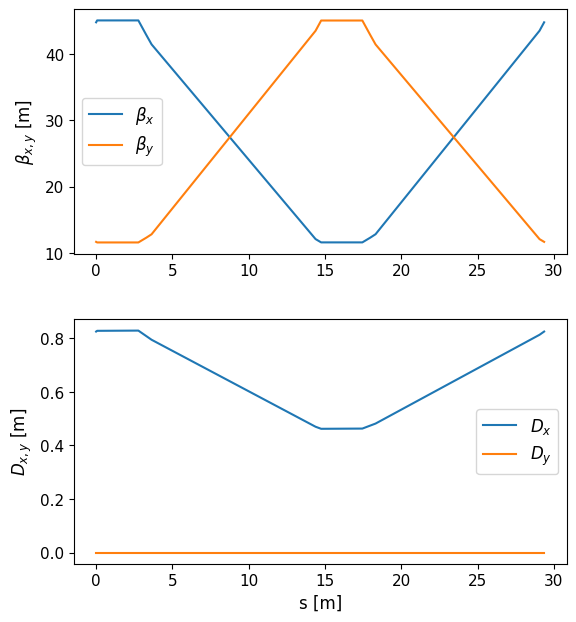

In [3]:
FODO_el, FODO_names, arc_el, arc_names=fodo(RCS=rcs,n_turn_rcs=n_turn_rcs ,length_sxt=L_sxt, 
                                            time_frac=time, option=option, n_slice=n_slice)

line_FODO=xt.Line(elements=FODO_el, element_names=FODO_names)
line_FODO.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                      q0=1, mass0=xp.MUON_MASS_EV)
tw_FODO=line_FODO.twiss(method='4d')
tw_init_FODO = tw_FODO.get_twiss_init('quad_f')
plot_twiss(tw_FODO)

In [6]:
line_tr=xt.Line(elements=arc_el, element_names=arc_names)
line_tr.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                    q0=1, mass0=xp.MUON_MASS_EV)

In [7]:
line_tr.get_table()


Table: 43 rows, 8 cols
name                     s element_type isthick isreplica parent_name iscollective env_name 
quad_d::0                0 Quadrupole      True     False None               False quad_d   
sxt_d::0               2.7 Sextupole       True     False None               False sxt_d    
drift_ext::0           3.2 Drift           True     False None               False drift_ext
drift_dd::0        3.26708 Drift           True     False None               False drift_dd 
BNC::0             3.56709 Bend            True     False None               False BNC      
drift_dd::1        14.3145 Drift           True     False None               False drift_dd 
drift_ext::1       14.6145 Drift           True     False None               False drift_ext
quad_f::0          14.6816 Quadrupole      True     False None               False quad_f   
sxt_f::0           17.3816 Sextupole       True     False None               False sxt_f    
drift_ext::2       17.8816 Drift           True

Working on a half-arc to match the dispersion suppressor. Working in transfer line mode 

In [7]:
line_tr.vars['kf1'] =  line_tr['quad_f'].k1  
line_tr.vars['kd1'] =  line_tr['quad_d'].k1 
line_tr.vars['kf2'] =   line_tr['quad_f'].k1
line_tr.vars['kd2'] =    line_tr['quad_d'].k1
line_tr.vars['kf3'] = line_tr['quad_f'].k1

line_tr.element_refs['quad_f::2'].k1 = line_tr.vars['kf3']
line_tr.element_refs['quad_f::1'].k1 = line_tr.vars['kf2']
line_tr.element_refs['quad::f'].k1 = line_tr.vars['kf1']

line_tr.element_refs['quad_d::1'].k1 = line_tr.vars['kd1']
line_tr.element_refs['quad_d::2'].k1 = line_tr.vars['kd2']

match_tr=line_tr.match(
            start='quad_f',
            end='marker_end', 
            init=tw_init_FODO,
            vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'], 
                            step=1e-8,
                            tag='quad'),
            targets=[xt.TargetSet(dx=0,dpx=0,alfx=0,alfy=0, at='marker_end',tol=1e-9)], 
            method='4d',
            solve=True
            )
# match_tr.step(50)
print('RESULTS FROM TR MATCHING')
match_tr.target_status()
match_tr.vary_status()

KeyError: 'quad_f::2'

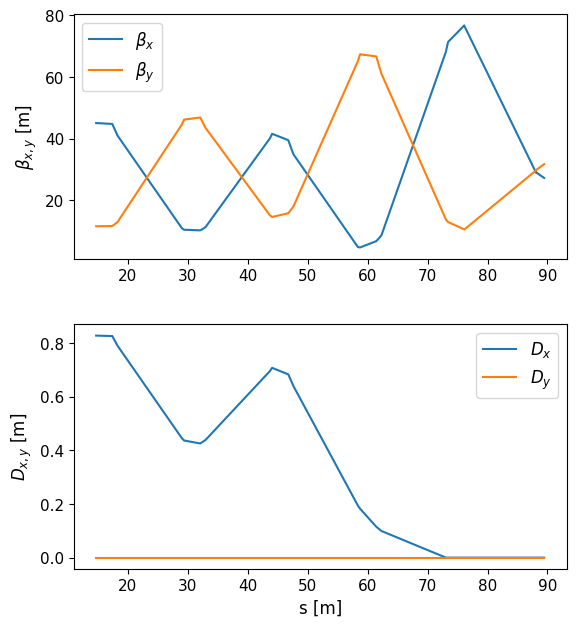

quad_d -0.03480406821010591
quad_f 0.03567914192688224
quad_d_1 -0.03291157805141173
quad_f_1 0.0434556630385572
quad_d_2 -0.034881241385885775
quad_f_2 0.03469889084954824
quad_d_half -0.03480406821010591


In [ ]:
tw_tr=line_tr.twiss(method='4d',  
            start='quad_f',
            end='marker_end', 
            init=tw_init_FODO)
plot_twiss(tw_tr)
tab_tr=line_tr.get_table()
for quad in tab_tr.rows[tab_tr.element_type == 'Quadrupole'].name:
    print(quad, line_tr[quad].k1)

Creating the full arc and checking the closure of the RCS and total circumference

In [ ]:
# import scipy.constants as sc
# print(rcs.h)
# print(1/(rcs.dipole_families['BNC']['tot_length']/2/np.pi))
# print(rcs.dipole_families['BNC']['B'](0)*(rcs.dipole_families['BNC']['tot_length']/2/np.pi))
# print(rcs.func_Brho(0))
# print(rcs.inj_Brho)
# print(line_FODO['BNC'].k0*rcs.injection_energy/sc.c)
# print(rcs.dipole_families['BNC']['B'](0))
# print(rcs.hn(0)*rcs.inj_Brho)

0.001719486521311374
0.0017195109890460608
209.36184897528247
209.36482812638997
210.14508443439564
0.36134214838258727
0.36
[0.36134164]


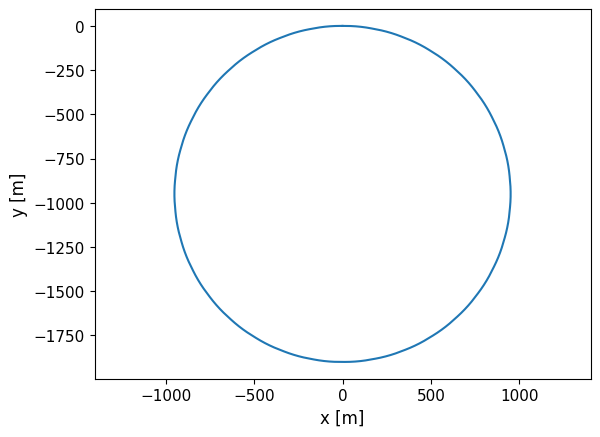

SURVEY RESULTS
X final 9.221901920738744e-12
Z final 5.526690216584029e-13
s total 5973.060704779824
Circumference 5990
Theta/2pi final -0.9999999999999999


In [9]:
tr=arc_el[2:]
tot_arc_el=tr[::-1]+arc_el
tr_name=arc_names[2:]
tot_arc_names=tr_name[::-1]+arc_names
line_tot=xt.Line(elements=tot_arc_el*rcs.nb_arc, element_names=tot_arc_names*rcs.nb_arc)
line_tot.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
line_tot.build_tracker()
survey=line_tot.survey()

plt.figure()
plt.plot(survey['Z'], survey['X'])
plt.axis('equal')
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()

print('SURVEY RESULTS')
print('X final', survey['X'][-1])
print('Z final', survey['Z'][-1])
print('s total', survey['s'][-1])
print('Circumference', rcs.circumference)
print('Theta/2pi final', survey['theta'][-1]/np.pi/2)

Creating the line of an arc

In [ ]:
line_ds=xt.Line(elements=tot_arc_el, element_names=tot_arc_names)
line_ds.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
tab_ds=line_ds.get_table()

Repetition found in `element_names` -> renaming


In [ ]:
line_ds.element_names

['marker_end',
 'quad_d_half',
 'RF_acc',
 'cavity',
 'drift_ins',
 'drift_ext',
 'quad_f',
 'drift_ext_1',
 'drift_dd',
 'BNC',
 'drift_dd_1',
 'drift_ext_2',
 'sxt_d',
 'quad_d',
 'drift_ext_3',
 'drift_dd_2',
 'BNC_1',
 'drift_dd_3',
 'drift_ext_4',
 'sxt_f',
 'quad_f_1',
 'drift_ext_5',
 'drift_dd_4',
 'BNC_2',
 'drift_dd_5',
 'drift_ext_6',
 'sxt_d_1',
 'quad_d_1',
 'drift_ext_7',
 'drift_dd_6',
 'BNC_3',
 'drift_dd_7',
 'drift_ext_8',
 'sxt_f_1',
 'quad_f_2',
 'drift_ext_9',
 'drift_dd_8',
 'BNC_4',
 'drift_dd_9',
 'drift_ext_10',
 'quad_d_2',
 'sxt_d_2',
 'drift_ext_11',
 'drift_dd_10',
 'BNC_5',
 'drift_dd_11',
 'drift_ext_12',
 'quad_f_3',
 'sxt_f_2',
 'drift_ext_13',
 'drift_dd_12',
 'BNC_6',
 'drift_dd_13',
 'drift_ext_14',
 'quad_d_3',
 'sxt_d_3',
 'drift_ext_15',
 'drift_dd_14',
 'BNC_7',
 'drift_dd_15',
 'drift_ext_16',
 'quad_f_4',
 'sxt_f_3',
 'drift_ext_17',
 'drift_dd_16',
 'BNC_8',
 'drift_dd_17',
 'drift_ext_18',
 'quad_d_4',
 'sxt_d_4',
 'drift_ext_19',
 'drift_dd_

Matching the dispersion suppressor on the arc from the transfer line results

In [ ]:
line_ds.vars['kf3'] = line_tr['quad_f_2'].k1
line_ds.vars['kf2'] = line_tr['quad_f_1'].k1
line_ds.vars['kf1'] = line_tr['quad_f'].k1
line_ds.vars['kd1'] = line_tr['quad_d_1'].k1
line_ds.vars['kd2'] = line_tr['quad_d_2'].k1

line_ds.element_refs['quad_f_5'].k1 = line_ds.vars['kf3'] 
# line_ds.element_refs['quad_f'].k1 = line_ds.vars['kf3'] 
line_ds.element_refs['quad_f_4'].k1 = line_ds.vars['kf2']
# line_ds.element_refs['quad_f_1'].k1 = line_ds.vars['kf2']
line_ds.element_refs['quad_f_3'].k1 = line_ds.vars['kf1'] 

line_ds.element_refs['quad_d_4'].k1 = line_ds.vars['kd2']
# line_ds.element_refs['quad_d'].k1 = line_ds.vars['kd2'] 
line_ds.element_refs['quad_d_3'].k1 = line_ds.vars['kd1']
# line_ds.element_refs['quad_d_1'].k1 = line_ds.vars['kd1']

match_ds=line_ds.match(
                vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'], 
                                step=1e-8,
                                tag='quad'),
                targets=[
                    xt.TargetSet(dx=0, at='marker_end', tol=1e-9),
                    xt.TargetSet(qx=1.543, qy=1.31,tol=1e-9),
                        ],
                method='6d',
                matrix_stability_tol=0.10,
                solve=False
                )
match_ds.step(50)
print('RESULTS FROM DS MATCHING')
match_ds.target_status()
match_ds.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.10)

RESULTS FROM DS MATCHING21               
Target status:                           
id state tag tol_met      residue current_val target_val description                                 
 0 ON           True  2.47786e-10 2.47786e-10          0 ('dx', 'marker_end'), val=0, tol=1e-09,  ...
 1 ON           True -9.03718e-10       1.543      1.543 'qx', val=1.543, tol=1e-09, weight=10       
 2 ON           True    1.223e-11        1.31       1.31 'qy', val=1.31, tol=1e-09, weight=10        
Vary status:                 
id state tag  met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    quad OK  kf1  None          0.0358563 None            0.0356791 1e-08      1
 1 ON    quad OK  kd1  None         -0.0339446 None           -0.0329116 1e-08      1
 2 ON    quad OK  kd2  None          -0.036463 None           -0.0348812 1e-08      1
 3 ON    quad OK  kf2  None          0.0438456 None            0.0434557 1e-08      1
 4 ON    quad OK  kf3  None          0.0355218 N

In [ ]:
# line_ds.vars['kf3'] = line_tr['quad_f_2'].k1
# line_ds.vars['kf2'] = line_tr['quad_f_1'].k1
# line_ds.vars['kf1'] = line_tr['quad_f'].k1
# line_ds.vars['kd1'] = line_tr['quad_d'].k1*0.95
# line_ds.vars['kd2'] = line_tr['quad_d_1'].k1*0.95

# line_ds.element_refs['quad_f_4'].k1 = line_ds.vars['kf3'] 
# # line_ds.element_refs['quad_f'].k1 = line_ds.vars['kf3'] 
# line_ds.element_refs['quad_f_3'].k1 = line_ds.vars['kf2']
# # line_ds.element_refs['quad_f_1'].k1 = line_ds.vars['kf2']
# line_ds.element_refs['quad_f_2'].k1 = line_ds.vars['kf1'] 

# line_ds.element_refs['quad_d_3'].k1 = line_ds.vars['kd2']
# # line_ds.element_refs['quad_d'].k1 = line_ds.vars['kd2'] 
# line_ds.element_refs['quad_d_2'].k1 = line_ds.vars['kd1']
# # line_ds.element_refs['quad_d_1'].k1 = line_ds.vars['kd1']

# match_ds=line_ds.match(
#                 vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'], 
#                                 step=1e-8,
#                                 tag='quad'),
#                 targets=[
#                     xt.TargetSet(dx=0, at='marker_end',tol=1e-9),
#                         ],
#                 method='6d',
#                 matrix_stability_tol=0.10,
#                 solve=False
#                 )
# match_ds.step(50)
# print('RESULTS FROM DS MATCHING')
# match_ds.target_status()
# match_ds.vary_status()

# tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.10)

Matching: model call n. 20               

RESULTS FROM TR MATCHING
Target status:                           
id state tag    tol_met      residue current_val target_val description                             
 0 ON    chroma    True -6.00694e-08    0.147059   0.147059 'dqx', val=0.147059, tol=1e-06, weight=1
 1 ON    chroma    True  3.10335e-13    0.147059   0.147059 'dqy', val=0.147059, tol=1e-06, weight=1
Vary status:                 
id state tag met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    sxt OK  sf   None           0.527145 None             0.339126 1e-06      1
 1 ON    sxt OK  sd   None          -0.959003 None             0.436503 1e-06      1


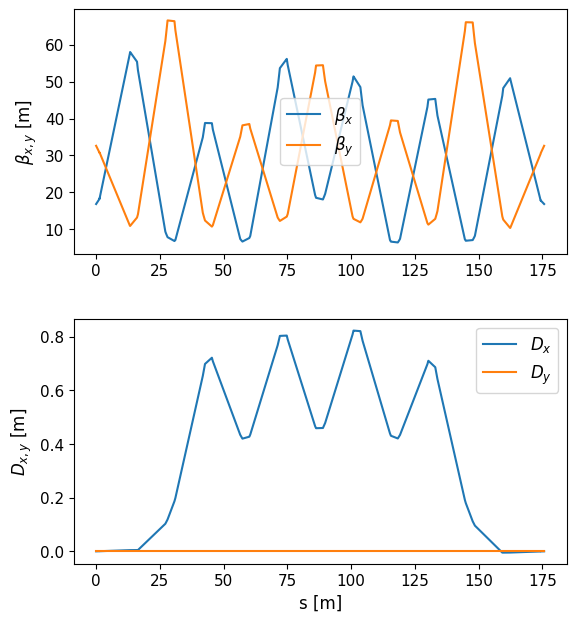

In [ ]:
line_ds.vars['sf'] = line_ds['quad_f_1'].k1*line_ds['quad_f_1'].length/tw_ds['dx','quad_f_1']/line_ds['sxt_f'].length
line_ds.vars['sd'] = -line_ds['quad_d_1'].k1*line_ds['quad_d_1'].length/tw_ds['dx','quad_d_1']/line_ds['sxt_d'].length

for sxt in tab_ds.rows[tab_ds.element_type=='Sextupole'].name:
    if 'sxt_d' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sd']
    elif 'sxt_f' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sf']
    
chroma_goal=5/rcs.nb_arc

match_ds_chroma=line_ds.match(
                vary=xt.VaryList(['sf','sd'], 
                                step=1e-6,
                                tag='sxt'),
                targets=[
                    xt.TargetSet(dqx=chroma_goal, dqy=chroma_goal, tol=1e-6, tag='chroma')
                    ],
                method='6d',
                matrix_stability_tol=0.1,
                solve=True
                )
print('RESULTS FROM TR MATCHING')
match_ds_chroma.target_status()
match_ds_chroma.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.1)
plot_twiss(tw_ds)

In [ ]:
tab=line_ds.get_table()
quad_k1=[]
sxt_k2=[]
for quad in tab.rows[tab.element_type == 'Quadrupole'].name:
    print(quad, line_ds[quad].k1)
    quad_k1.append(line_ds[quad].k1)
for sxt in tab.rows[tab.element_type == 'Sextupole'].name:
    print(sxt, line_ds[sxt].k2)
    sxt_k2.append(line_ds[sxt].k2)
print(max(np.absolute(quad_k1)), max(np.absolute(sxt_k2)))

quad_d_half -0.03480406821010591
quad_f 0.0355218141780501
quad_d -0.03646303989229953
quad_f_1 0.04384557363883276
quad_d_1 -0.03394457092138491
quad_f_2 0.03585629089885814
quad_d_2 -0.03480406821010591
quad_f_3 0.03585629089885814
quad_d_3 -0.03394457092138491
quad_f_4 0.04384557363883276
quad_d_4 -0.03646303989229953
quad_f_5 0.0355218141780501
quad_d_half_1 -0.03480406821010591
sxt_d -0.9590034078926317
sxt_f 0.527144890670075
sxt_d_1 -0.9590034078926317
sxt_f_1 0.527144890670075
sxt_d_2 -0.9590034078926317
sxt_f_2 0.527144890670075
sxt_d_3 -0.9590034078926317
sxt_f_3 0.527144890670075
sxt_d_4 -0.9590034078926317
0.04384557363883276 0.9590034078926317


Printing some global parameters: dipole lengths, dipole aperture, qp aperture, path length difference ....

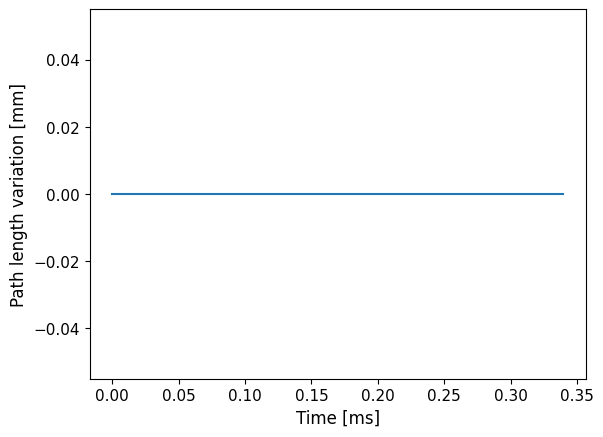

GLOBAL PARAMETER
C 5990
NB arc 34
Nb of cells per arc 5
Cell length 30.09894117647059
Longueur totale NC 3654.053592681795
FF arc 0.854
Dipole FF 0.61
MCF 0.000468
Transition gamma 46.24
Qs 0.665
Qx 52.462
Qy 44.54
dqx 5.0
dqy 5.0
pattern ['BNC']
Length NC 10.75 m
Horizontal beam size 91.1 mm
Vertical beam size 20.0 mm
Vertical aperture 40.0 mm
Length QP 2.7 m
QP Bpole for 50mm apert 1.15 T
Extra length QP 0.13 m
Length SXT 0.5 m
SXT Bpole for 50mm apert 0.31 T


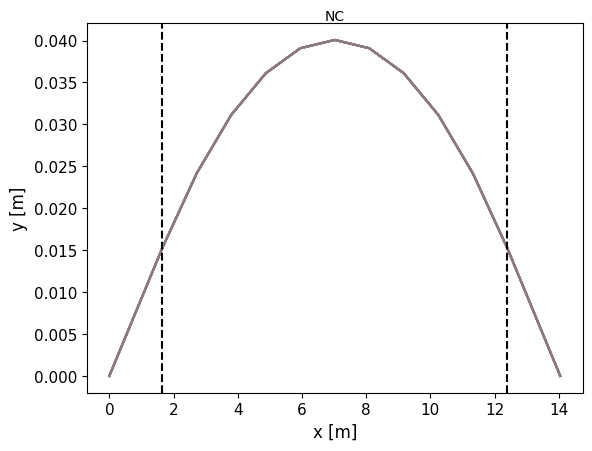

In [ ]:
delta = 44e-3
max_path_diff=plot_path_diff(rcs, n_turn_rcs)
hor_size_beam=size_beam_diam_hor(tw_ds, rcs,delta)
vert_size_beam=size_beam_diam_vert(tw_ds, rcs,delta)
apert_V=vert_apert(tw_ds, rcs,delta)
print('GLOBAL PARAMETER')
print('C', rcs.circumference)
print('NB arc', rcs.nb_arc)
print('Nb of cells per arc', rcs.nb_cell_arc)
print('Cell length', rcs.cell_length)
print('Longueur totale NC', rcs.dipole_families['BNC']['tot_length'])
if rcs.type == 'hybrid':
    print('Longueur totale SC', rcs.dipole_families['BSC']['tot_length'])
print('FF arc', np.round(rcs.filling_ratio,3))
print('Dipole FF', np.round(rcs.filling_ratio_dipole,3))
print('MCF', round(tw_ds['momentum_compaction_factor'], 6))
print('Transition gamma', np.round(1/np.sqrt(tw_ds['momentum_compaction_factor']),2))
print('Qs', round(tw_ds['qs']*rcs.nb_arc, 3))
print('Qx', round(tw_ds['qx']*rcs.nb_arc, 3))
print('Qy', round(tw_ds['qy']*rcs.nb_arc, 3))
print('dqx', round(tw_ds['dqx']*rcs.nb_arc, 2))
print('dqy', round(tw_ds['dqy']*rcs.nb_arc, 2))
print('pattern', rcs.pattern)
if rcs.type == 'hybrid':
    print('Max path length diff', round(max_path_diff*1e3,1), 'mm')
    print('Relative path length diff', round(max_path_diff/rcs.circumference*1e6,2), 'e-6')
    print('Traj excursion SC', round(rcs.width_sc_opt*1e3,0), 'mm')
    print('Hor apert SC', round((rcs.width_sc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
    # print('Apert SC', round(rcs.aperture_sc_opt*1e3,0), 'mm')
    print('Length SC', round(rcs.dipole_families['BSC']['length'],2), 'm')
    print('Traj excursion NC', round(rcs.width_nc_opt*1e3,0), 'mm')
    # print('Apert NC', round(rcs.aperture_nc_opt*1e3,0), 'mm')
    print('Hor apert NC', round((rcs.width_nc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
print('Length NC', round(rcs.dipole_families['BNC']['length'],2), 'm')
print('Horizontal beam size', round(hor_size_beam*1e3,1), 'mm')
print('Vertical beam size', round(vert_size_beam*1e3,1), 'mm')
print('Vertical aperture', round(apert_V*1e3,1), 'mm')
print('Length QP', round(line_ds['quad_d'].length,2), 'm')
print('QP Bpole for 50mm apert', round(max(np.absolute(quad_k1))*rcs.ext_Brho*(25e-3),2), 'T')
print('Extra length QP', round(line_ds['drift_ext'].length*2,2), 'm')
print('Length SXT', round(line_ds['sxt_d'].length,2), 'm')
print('SXT Bpole for 50mm apert', round(max(np.absolute(sxt_k2))/2*rcs.ext_Brho*(25e-3)**2,2), 'T')

rcs.plot_traj()

In [ ]:
# para = {  "type": rcs.type,
#    "circumference": rcs.circumference,
#    "injection_energy": rcs.injection_energy,
#    "extraction_energy": rcs.extraction_energy,
#    "length_short_insertion": rcs.length_short_insertion,
#    "dipole_spacing": rcs.dipole_spacing,
#    "nb_RF_section": rcs.nb_RF_section,
#    "nb_arc": rcs.nb_arc,
#    "nb_cell_arc": rcs.nb_cell_arc,
#    "dipoles": rcs.dipoles,
#    "filling_ratio": rcs.filling_ratio,
#    "filling_ratio_RF": rcs.filling_ratio_RF,
#    "pattern": rcs.pattern
# }
# with open('para_RCS1_opt_5nc.json', 'w') as file:
#     json.dump(para, file, indent=4)
# line_ds.to_json('/mnt/c/muco/code/lattice/RCS1_DS_inj_5nc.json')